# Praktikum 5 - Evaluasi Metrik ANN: Trade-off Recall vs Latensi

**Mata Kuliah:** Pembelajaran Mesin
**Jobsheet 06:** ANN (Approximate Nearest Neighbors)

### Tujuan Praktikum:
1. Memahami kurva *Precision-Recall vs Query Speed* pada algoritma ANN.
2. Mengevaluasi metrik **Recall@k**:
   $$\text{Recall@k} = \frac{|\text{Exact NN} \cap \text{Approx NN}|}{k}$$
3. Memvisualisasikan trade-off antara kecepatan pencarian (*Queries Per Second / QPS*) dan akurasi recall.

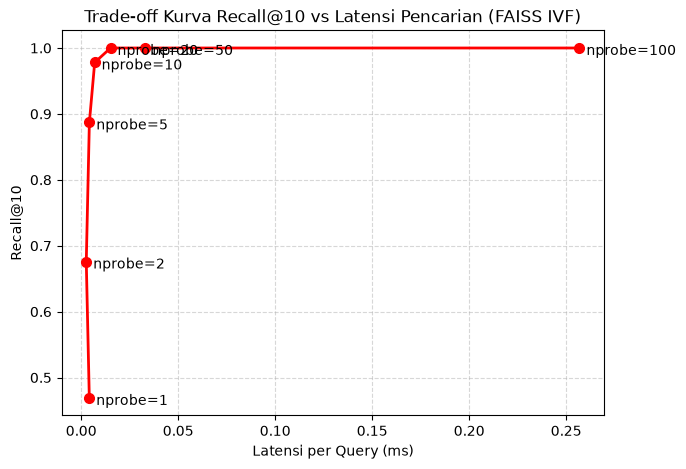

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import faiss
import time

# Simulasi trade-off nprobe pada FAISS IVF
np.random.seed(42)
X = np.random.rand(50000, 10).astype('float32')
queries = np.random.rand(100, 10).astype('float32')
k = 10

# Ground Truth (Exact)
exact_idx = faiss.IndexFlatL2(10)
exact_idx.add(X)
_, gt_indices = exact_idx.search(queries, k)

# FAISS IVF Index
quantizer = faiss.IndexFlatL2(10)
ivf = faiss.IndexIVFFlat(quantizer, 10, 100, faiss.METRIC_L2)
ivf.train(X)
ivf.add(X)

nprobes = [1, 2, 5, 10, 20, 50, 100]
recalls = []
latencies = []

for np_val in nprobes:
    ivf.nprobe = np_val
    start = time.time()
    _, pred_indices = ivf.search(queries, k)
    t = (time.time() - start) / len(queries) * 1000
    latencies.append(t)
    
    # Hitung Recall@k rata-rata
    rec = np.mean([len(set(gt_indices[i]).intersection(set(pred_indices[i]))) / k for i in range(len(queries))])
    recalls.append(rec)

plt.figure(figsize=(7, 5))
plt.plot(latencies, recalls, 'ro-', linewidth=2, markersize=7)
for i, np_val in enumerate(nprobes):
    plt.annotate(f'nprobe={np_val}', (latencies[i], recalls[i]), textcoords='offset points', xytext=(5, -5))
plt.title('Trade-off Kurva Recall@10 vs Latensi Pencarian (FAISS IVF)')
plt.xlabel('Latensi per Query (ms)')
plt.ylabel('Recall@10')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()